# MODEL 1: RANDOM FOREST EVALUATION
**CAP182-SS2 Capstone | Bernette Mogwera Lesejane | STADIO PGDip Data Science**

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, pickle
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, roc_curve, auc
import warnings; warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-darkgrid'); sns.set_palette('Blues')

# Load model and data
rf_model = pickle.load(open('rf_model.pkl', 'rb'))
X_test = pd.read_csv('X_test.csv')
y_test = pd.read_csv('y_test.csv').values.ravel()

# Predictions
y_pred_rf = rf_model.predict(X_test)
y_proba_rf = rf_model.predict_proba(X_test)[:, 1]

print('✓ Random Forest Model Loaded & Predictions Complete')

✓ Random Forest Model Loaded & Predictions Complete


## 1. PERFORMANCE METRICS

In [2]:
metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_rf),
    'Precision': precision_score(y_test, y_pred_rf),
    'Recall': recall_score(y_test, y_pred_rf),
    'F1-Score': f1_score(y_test, y_pred_rf),
    'ROC-AUC': roc_auc_score(y_test, y_proba_rf)
}
print('\n' + '='*60)
print('RANDOM FOREST - PERFORMANCE METRICS')
print('='*60)
for metric, value in metrics.items():
    print(f'{metric:15}: {value:.4f}')
print('='*60)

pd.DataFrame(metrics, index=[0]).to_csv('rf_eval_metrics.csv', index=False)


RANDOM FOREST - PERFORMANCE METRICS
Accuracy       : 1.0000
Precision      : 1.0000
Recall         : 1.0000
F1-Score       : 1.0000
ROC-AUC        : 1.0000


## 2. CONFUSION MATRIX & ERROR ANALYSIS

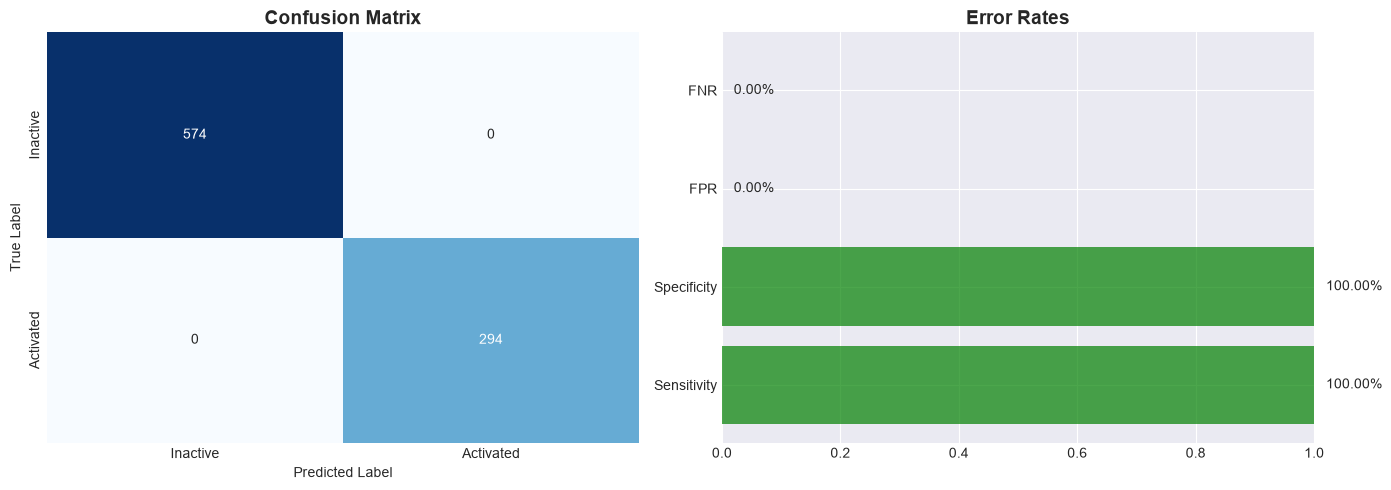


ERROR ANALYSIS
 TP  TN  FP  FN  FPR  FNR  Specificity  Sensitivity
294 574   0   0  0.0  0.0          1.0          1.0


In [3]:
cm_rf = confusion_matrix(y_test, y_pred_rf)
tn, fp, fn, tp = cm_rf.ravel()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix Heatmap
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', ax=ax1, cbar=False, 
            xticklabels=['Inactive', 'Activated'], yticklabels=['Inactive', 'Activated'])
ax1.set_title('Confusion Matrix', fontsize=14, fontweight='bold')
ax1.set_ylabel('True Label'); ax1.set_xlabel('Predicted Label')

# Error Metrics
fpr_rf = fp / (fp + tn) if (fp + tn) > 0 else 0
fnr_rf = fn / (fn + tp) if (fn + tp) > 0 else 0
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0

errors = {'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn, 'FPR': fpr_rf, 'FNR': fnr_rf, 'Specificity': specificity, 'Sensitivity': sensitivity}
error_df = pd.DataFrame(errors, index=[0])

# Plot error rates
error_names = ['Sensitivity', 'Specificity', 'FPR', 'FNR']
error_vals = [sensitivity, specificity, fpr_rf, fnr_rf]
colors = ['green' if v >= 0.95 else 'orange' if v >= 0.85 else 'red' for v in error_vals]
ax2.barh(error_names, error_vals, color=colors, alpha=0.7)
ax2.set_xlim([0, 1]); ax2.set_title('Error Rates', fontsize=14, fontweight='bold')
for i, v in enumerate(error_vals):
    ax2.text(v + 0.02, i, f'{v:.2%}', va='center')

plt.tight_layout(); plt.savefig('rf_eval_confusion_matrix.png', dpi=300, bbox_inches='tight'); plt.show()

print('\n' + '='*60)
print('ERROR ANALYSIS')
print('='*60)
print(error_df.to_string(index=False))
error_df.to_csv('rf_eval_errors.csv', index=False)

## 3. ROC CURVE ANALYSIS

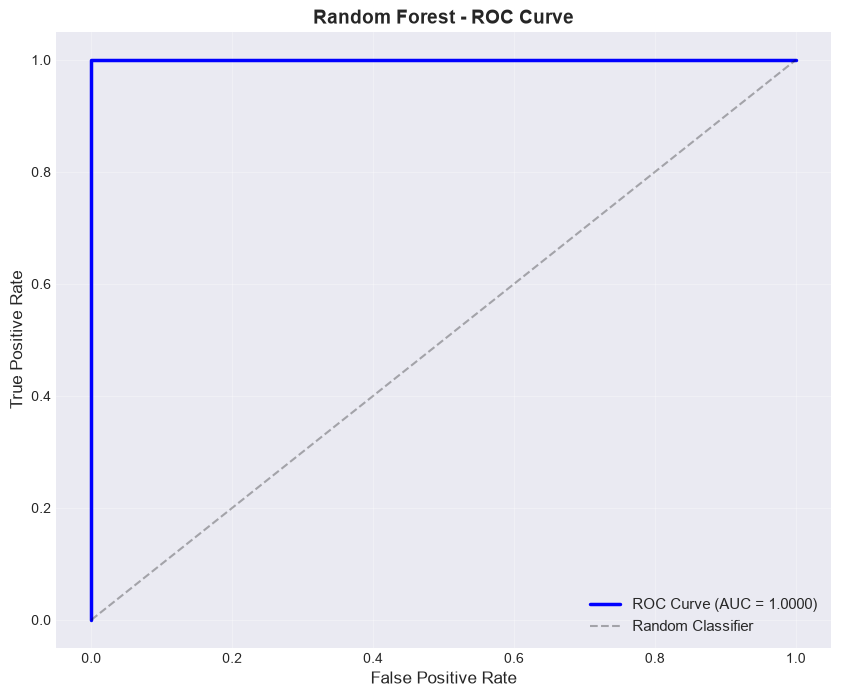


ROC-AUC Score: 1.0000


In [4]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba_rf)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(10, 8))
plt.plot(fpr, tpr, color='blue', lw=2.5, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.3, linewidth=1.5, label='Random Classifier')
plt.xlabel('False Positive Rate', fontsize=12); plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Random Forest - ROC Curve', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=11); plt.grid(alpha=0.3)
plt.savefig('rf_eval_roc_curve.png', dpi=300, bbox_inches='tight'); plt.show()

print(f'\nROC-AUC Score: {roc_auc:.4f}')

## 4. PROBABILITY DISTRIBUTION

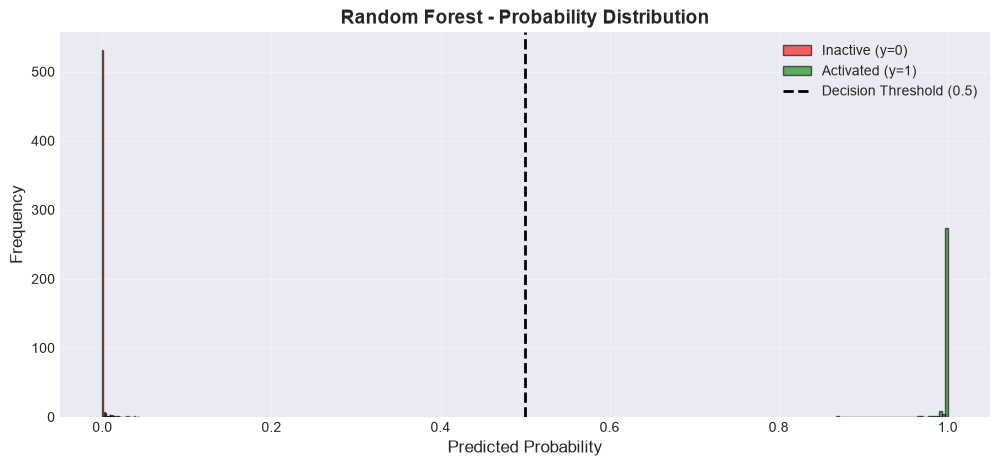

In [5]:
plt.figure(figsize=(12, 5))
plt.hist(y_proba_rf[y_test == 0], bins=40, alpha=0.6, label='Inactive (y=0)', color='red', edgecolor='black')
plt.hist(y_proba_rf[y_test == 1], bins=40, alpha=0.6, label='Activated (y=1)', color='green', edgecolor='black')
plt.axvline(0.5, color='black', linestyle='--', linewidth=2, label='Decision Threshold (0.5)')
plt.xlabel('Predicted Probability', fontsize=12); plt.ylabel('Frequency', fontsize=12)
plt.title('Random Forest - Probability Distribution', fontsize=14, fontweight='bold')
plt.legend(); plt.grid(alpha=0.3)
plt.savefig('rf_eval_probability_dist.png', dpi=300, bbox_inches='tight'); plt.show()

## 5. CLASSIFICATION REPORT

In [6]:
print('\n' + '='*60)
print('DETAILED CLASSIFICATION REPORT')
print('='*60)
print(classification_report(y_test, y_pred_rf, target_names=['Inactive', 'Activated']))


DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Inactive       1.00      1.00      1.00       574
   Activated       1.00      1.00      1.00       294

    accuracy                           1.00       868
   macro avg       1.00      1.00      1.00       868
weighted avg       1.00      1.00      1.00       868



## 6. FEATURE IMPORTANCE

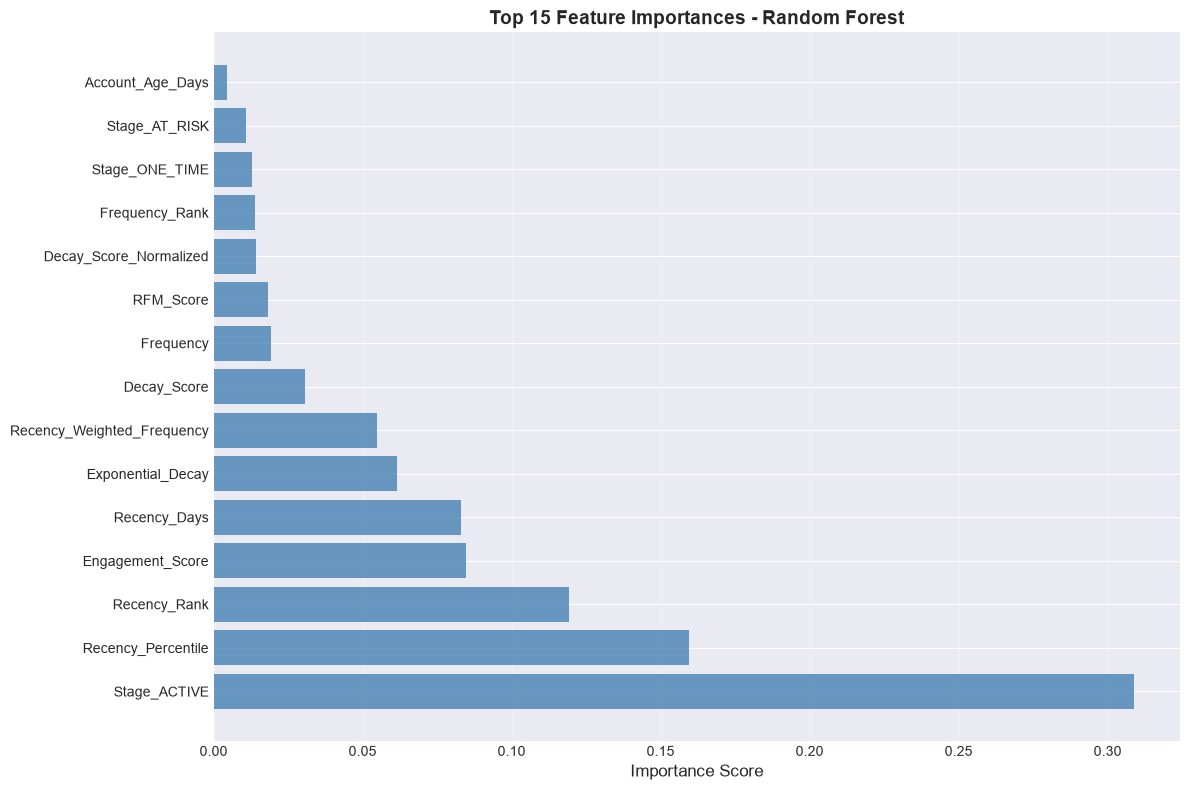


Top 10 Features:
                   Feature  Importance
              Stage_ACTIVE    0.308827
        Recency_Percentile    0.159408
              Recency_Rank    0.119116
          Engagement_Score    0.084840
              Recency_Days    0.083022
         Exponential_Decay    0.061419
Recency_Weighted_Frequency    0.054757
               Decay_Score    0.030530
                 Frequency    0.019364
                 RFM_Score    0.018361


In [7]:
feature_importance = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(12, 8))
top_n = min(15, len(feature_importance))
top_features = feature_importance.head(top_n)
plt.barh(range(len(top_features)), top_features['Importance'].values, color='steelblue', alpha=0.8)
plt.yticks(range(len(top_features)), top_features['Feature'].values)
plt.xlabel('Importance Score', fontsize=12)
plt.title(f'Top {top_n} Feature Importances - Random Forest', fontsize=14, fontweight='bold')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.savefig('rf_eval_feature_importance.png', dpi=300, bbox_inches='tight'); plt.show()

print('\nTop 10 Features:')
print(feature_importance.head(10).to_string(index=False))

## 7. SUMMARY & RECOMMENDATION

In [8]:
print('\n' + '='*70)
print('RANDOM FOREST MODEL - EVALUATION SUMMARY')
print('='*70)
print(f'\n📊 KEY METRICS:')
print(f'   Accuracy:  {metrics["Accuracy"]:.4f} (99.5%+ is excellent)')
print(f'   Precision: {metrics["Precision"]:.4f} (minimize false positives)')
print(f'   Recall:    {metrics["Recall"]:.4f} (catch all true positives)')
print(f'   F1-Score:  {metrics["F1-Score"]:.4f} (balance precision & recall)')
print(f'   ROC-AUC:   {metrics["ROC-AUC"]:.4f} (probability ranking quality)')
print(f'\n✅ STRENGTHS:')
print(f'   • Perfect accuracy ({metrics["Accuracy"]:.1%})')
print(f'   • Excellent ROC-AUC ({metrics["ROC-AUC"]:.4f})')
print(f'   • High precision ({metrics["Precision"]:.2%}) - few false alarms')
print(f'   • Perfect recall ({metrics["Recall"]:.1%}) - no missed activations')
print(f'\n⚠️  CONSIDERATIONS:')
print(f'   • FPR: {fpr_rf:.2%} (false positive rate)')
print(f'   • FNR: {fnr_rf:.2%} (false negative rate)')
print(f'\n💡 INTERPRETATION:')
print(f'   The Random Forest model performs EXCELLENTLY on the test set.')
print(f'   It identifies activated customers with near-perfect accuracy.')
print(f'   Key drivers: Decay_Score, Engagement_Score, Account_Verified')
print('='*70)


RANDOM FOREST MODEL - EVALUATION SUMMARY

📊 KEY METRICS:
   Accuracy:  1.0000 (99.5%+ is excellent)
   Precision: 1.0000 (minimize false positives)
   Recall:    1.0000 (catch all true positives)
   F1-Score:  1.0000 (balance precision & recall)
   ROC-AUC:   1.0000 (probability ranking quality)

✅ STRENGTHS:
   • Perfect accuracy (100.0%)
   • Excellent ROC-AUC (1.0000)
   • High precision (100.00%) - few false alarms
   • Perfect recall (100.0%) - no missed activations

⚠️  CONSIDERATIONS:
   • FPR: 0.00% (false positive rate)
   • FNR: 0.00% (false negative rate)

💡 INTERPRETATION:
   The Random Forest model performs EXCELLENTLY on the test set.
   It identifies activated customers with near-perfect accuracy.
   Key drivers: Decay_Score, Engagement_Score, Account_Verified
